First five rows:
   age  sex   BP  cholestrol  heart disease
0   70    1  130         322              1
1   67    0  115         564              0
2   57    1  124         261              1
3   64    1  128         263              0
4   74    0  120         269              0

Dataset shape: (270, 5)

Missing values:
age              0
sex              0
BP               0
cholestrol       0
heart disease    0
dtype: int64

Target distribution:
heart disease
0    150
1    120
Name: count, dtype: int64


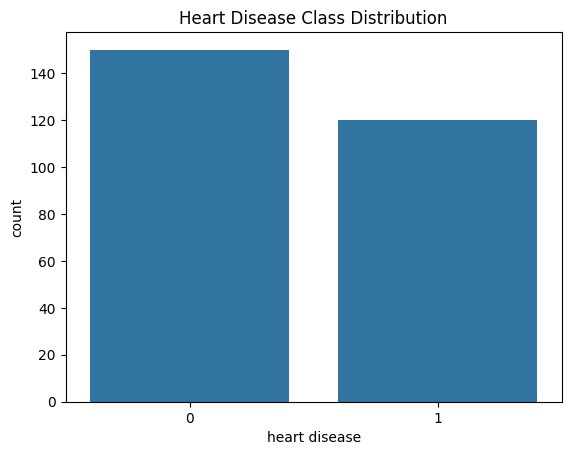

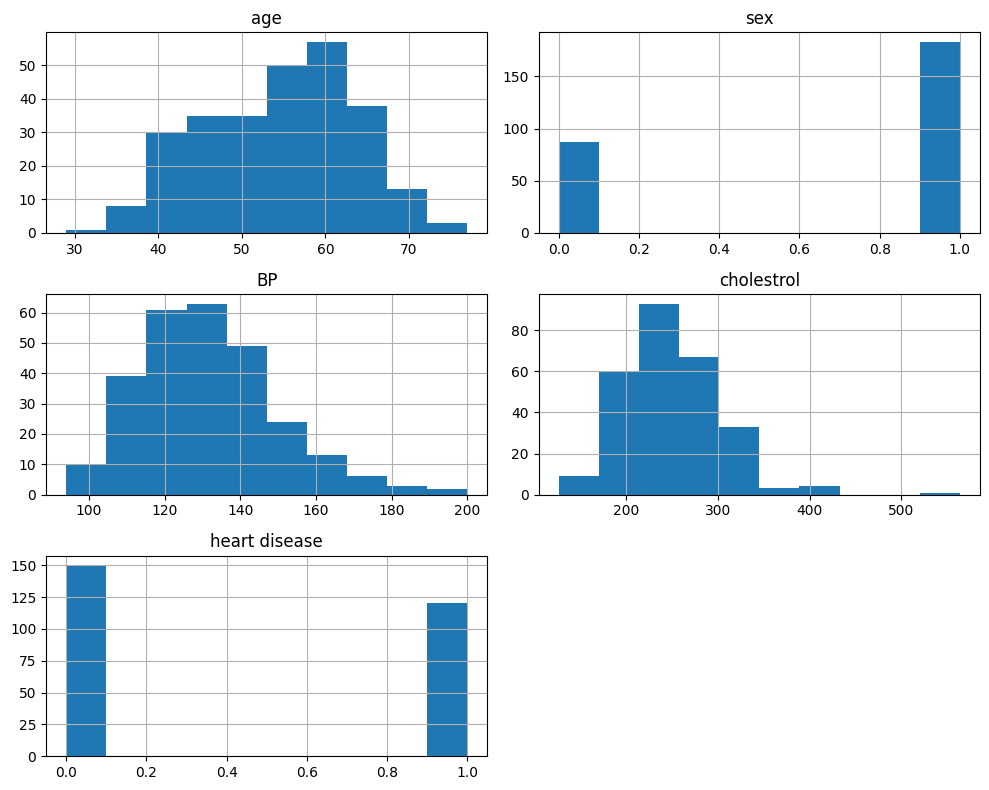


Accuracy: 0.6481481481481481
Precision: 0.5862068965517241
Recall: 0.7083333333333334
F1 Score: 0.6415094339622641

Classification Report:
              precision    recall  f1-score   support

           0       0.72      0.60      0.65        30
           1       0.59      0.71      0.64        24

    accuracy                           0.65        54
   macro avg       0.65      0.65      0.65        54
weighted avg       0.66      0.65      0.65        54


Confusion Matrix:
[[18 12]
 [ 7 17]]


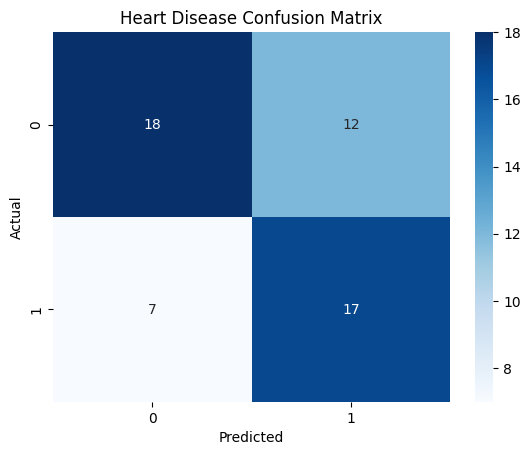

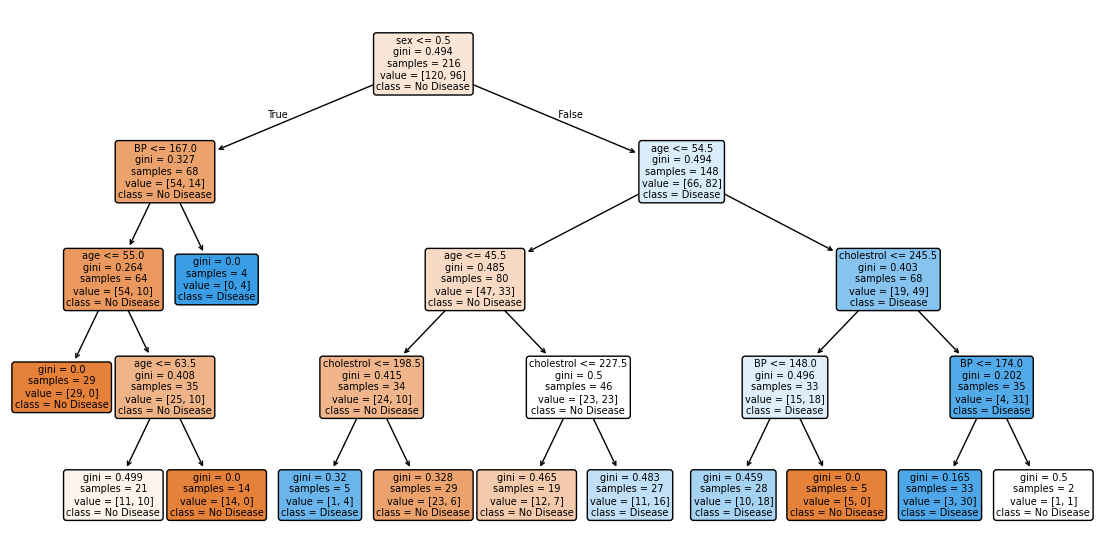


Sample Prediction:
No Disease


In [1]:

import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix, classification_report

df = pd.read_csv("heart_v2.csv")

print("First five rows:")
print(df.head())

print("\nDataset shape:", df.shape)
print("\nMissing values:")
print(df.isnull().sum())

print("\nTarget distribution:")
print(df["heart disease"].value_counts())

sns.countplot(data=df, x="heart disease")
plt.title("Heart Disease Class Distribution")
plt.show()

df.hist(figsize=(10, 8))
plt.tight_layout()
plt.show()

X = df.drop("heart disease", axis=1)
y = df["heart disease"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

model = DecisionTreeClassifier(
    criterion="gini", max_depth=4, random_state=42
)

model.fit(X_train, y_train)

y_pred = model.predict(X_test)

print("\nAccuracy:", accuracy_score(y_test, y_pred))
print("Precision:", precision_score(y_test, y_pred, zero_division=0))
print("Recall:", recall_score(y_test, y_pred, zero_division=0))
print("F1 Score:", f1_score(y_test, y_pred, zero_division=0))

print("\nClassification Report:")
print(classification_report(y_test, y_pred, zero_division=0))

cm = confusion_matrix(y_test, y_pred)

print("\nConfusion Matrix:")
print(cm)

sns.heatmap(cm, annot=True, fmt="d", cmap="Blues")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Heart Disease Confusion Matrix")
plt.show()

plt.figure(figsize=(14, 7))
plot_tree(
    model,
    feature_names=X.columns,
    class_names=["No Disease", "Disease"],
    filled=True,
    rounded=True
)
plt.show()

print("\nSample Prediction:")
print("Disease" if model.predict(X_test.iloc[[0]])[0] == 1 else "No Disease")
